# Results of the final experiments

Reads the runs submitted by `jobs/run_experiments.sh` (4 conditions × 4 sizes × 3 seeds) and shows:
1. the dev BLEU of every condition and size (mean ± std over seeds),
2. the train and dev loss curves,
3. each condition minus uniform, paired by seed,
4. test-set scores (WMT22, Tatoeba) for greedy and beam 4 decoding, and the gain from beam search.

```
results/_evaluation_workflow/summary.csv          test-set BLEU / chrF / COMET of every run
runs/<condition>_n<size>_seed<seed>/run_info.json   settings + final scores
runs/<condition>_n<size>_seed<seed>/dev_curve.csv   train/dev loss every eval_every steps
```

In [2]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Paths below are relative to the repository root.
if Path.cwd().name == "notebooks":
    os.chdir("..")

RUNS_DIR = Path("runs")
CONDITIONS = ["uniform", "length", "joint", "loss"]
SIZES = ["1000", "2000", "5000", "full"]
COLOUR = {"uniform": "#2a78d6", "length": "#e07b39", "joint": "#3a9e6f", "loss": "#8e5bc4"}

## 1. Load every run

In [3]:
rows = []
for info_file in sorted(RUNS_DIR.glob("*/run_info.json")):
    info = json.loads(info_file.read_text())
    rows.append(
        {
            "condition": info["condition"],
            "size": info["size"],
            "seed": info["seed"],
            "best_step": info["best_step"],
            "steps": info["steps"],
            "dev_loss": info["best_dev_loss"],
            "dev_bleu": info["dev_bleu_greedy"],
            "run_dir": info_file.parent,
        }
    )
runs = pd.DataFrame(rows)
print(f"found {len(runs)} of {len(CONDITIONS) * len(SIZES) * 3} runs")

found 48 of 48 runs


## 2. Dev BLEU

Greedy BLEU on the dev set at the selected checkpoint (lowest dev loss). Mean ± std over the 3 seeds.

In [4]:
stats = runs.groupby(["size", "condition"])["dev_bleu"].agg(["mean", "std"])
table = (stats["mean"].map("{:.2f}".format) + " ± " + stats["std"].map("{:.2f}".format)).unstack()
table.reindex(index=SIZES, columns=CONDITIONS)

condition,uniform,length,joint,loss
size,,,,
1000,14.91 ± 0.06,15.02 ± 0.13,14.90 ± 0.11,14.81 ± 0.04
2000,15.01 ± 0.16,14.91 ± 0.10,14.81 ± 0.17,14.82 ± 0.14
5000,15.35 ± 0.16,15.17 ± 0.07,15.36 ± 0.16,15.12 ± 0.08
full,16.16 ± 0.14,16.00 ± 0.08,15.77 ± 0.03,15.83 ± 0.06


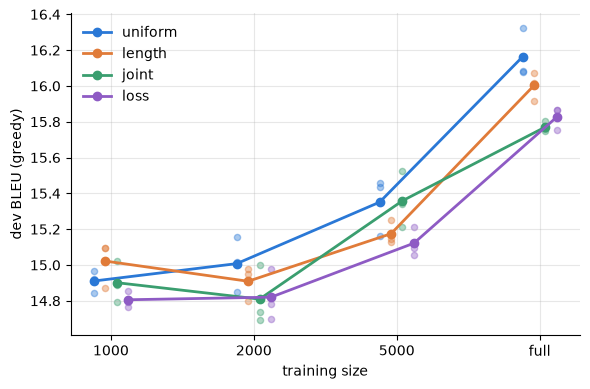

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
x = {size: i for i, size in enumerate(SIZES)}
for k, condition in enumerate(CONDITIONS):
    sub = runs[runs["condition"] == condition]
    offset = (k - (len(CONDITIONS) - 1) / 2) * 0.08  # spread conditions a little so the seed dots don't overlap
    ax.scatter(sub["size"].map(x) + offset, sub["dev_bleu"], color=COLOUR[condition], alpha=0.4, s=20)
    mean = sub.groupby("size")["dev_bleu"].mean().reindex(SIZES)
    ax.plot([x[s] + offset for s in SIZES], mean, "o-", color=COLOUR[condition], linewidth=2, label=condition)
ax.set_xticks(range(len(SIZES)), SIZES)
ax.set_xlabel("training size")
ax.set_ylabel("dev BLEU (greedy)")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 3. Loss curves

Rows = size, columns = condition, one pair of lines per seed. Solid = dev loss, dashed = train loss
(averaged over the steps since the previous evaluation). The dot is the selected checkpoint.

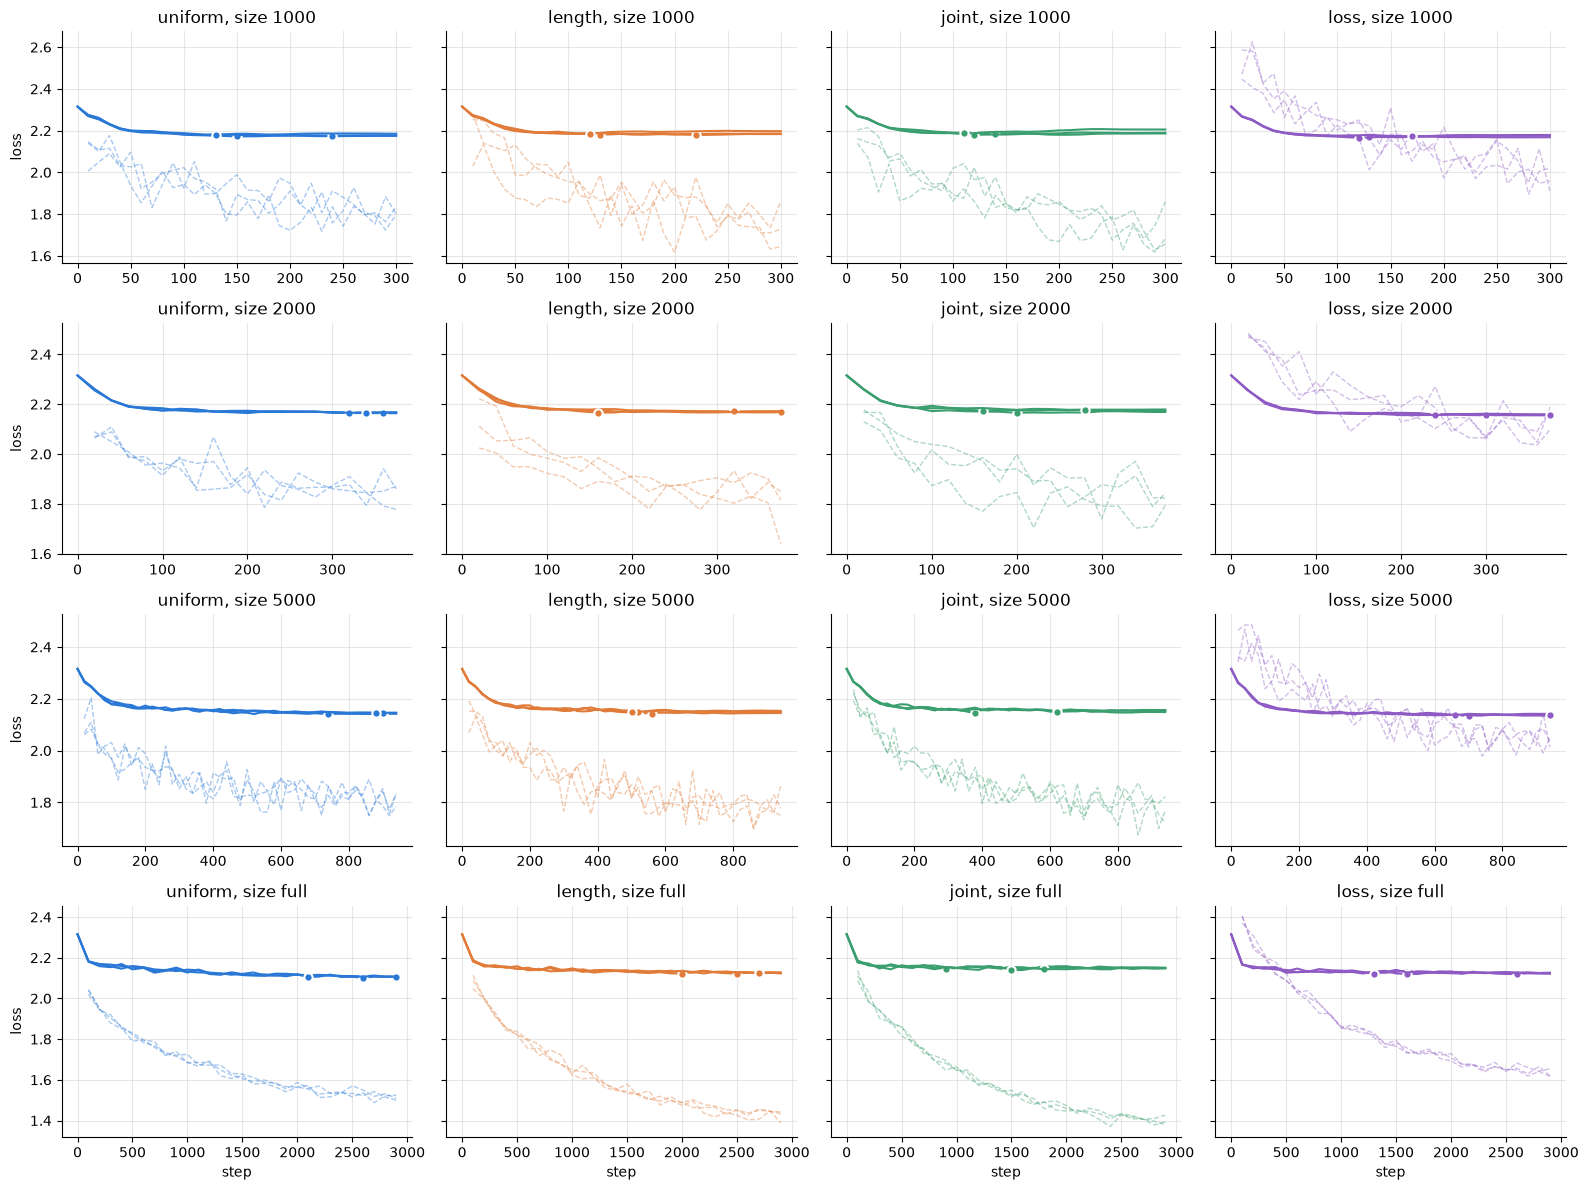

In [6]:
fig, axes = plt.subplots(len(SIZES), len(CONDITIONS), figsize=(4 * len(CONDITIONS), 3 * len(SIZES)),
                         sharey="row", squeeze=False)
for i, size in enumerate(SIZES):
    for j, condition in enumerate(CONDITIONS):
        ax = axes[i, j]
        colour = COLOUR[condition]
        for _, run in runs[(runs["size"] == size) & (runs["condition"] == condition)].iterrows():
            curve = pd.read_csv(run["run_dir"] / "dev_curve.csv")
            ax.plot(curve["step"], curve["train_loss"], "--", color=colour, alpha=0.4, linewidth=1)
            ax.plot(curve["step"], curve["dev_loss"], color=colour, linewidth=1.5)
            ax.plot(run["best_step"], run["dev_loss"], "o", color=colour, markersize=6,
                    markeredgecolor="white", markeredgewidth=1.5)
        ax.set_title(f"{condition}, size {size}")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
for ax in axes[-1]:
    ax.set_xlabel("step")
for ax in axes[:, 0]:
    ax.set_ylabel("loss")
fig.tight_layout()
plt.show()

# Evaluation on test set

## 4. Each condition vs uniform

Same subset and seed, only the sampling weights differ, so the fair comparison is paired:
condition minus uniform for each seed, then mean ± std over the 3 seeds. Positive dev BLEU / negative
dev loss = better than uniform. With 3 seeds, a mean difference smaller than its std is noise.

In [7]:
base = runs[runs["condition"] == "uniform"].set_index(["size", "seed"])[["dev_bleu", "dev_loss"]]
diffs = []
for condition in CONDITIONS[1:]:
    sub = runs[runs["condition"] == condition].set_index(["size", "seed"])[["dev_bleu", "dev_loss"]]
    d = (sub - base).dropna().reset_index()
    d["condition"] = condition
    diffs.append(d)
diffs = pd.concat(diffs)

for metric, fmt in [("dev_bleu", "{:+.2f}"), ("dev_loss", "{:+.4f}")]:
    s = diffs.groupby(["size", "condition"])[metric].agg(["mean", "std"])
    t = (s["mean"].map(fmt.format) + " ± " + s["std"].map("{:.2f}".format if metric == "dev_bleu" else "{:.4f}".format)).unstack()
    print(f"{metric}: condition minus uniform (mean ± std over seeds)")
    display(t.reindex(index=SIZES, columns=CONDITIONS[1:]))

dev_bleu: condition minus uniform (mean ± std over seeds)


condition,length,joint,loss
size,,,
1000,+0.11 ± 0.07,-0.01 ± 0.16,-0.10 ± 0.08
2000,-0.10 ± 0.20,-0.20 ± 0.20,-0.19 ± 0.17
5000,-0.18 ± 0.13,+0.01 ± 0.31,-0.23 ± 0.13
full,-0.16 ± 0.09,-0.39 ± 0.11,-0.34 ± 0.20


dev_loss: condition minus uniform (mean ± std over seeds)


condition,length,joint,loss
size,,,
1000,+0.0072 ± 0.0017,+0.0098 ± 0.0036,-0.0059 ± 0.0020
2000,+0.0032 ± 0.0021,+0.0071 ± 0.0050,-0.0087 ± 0.0013
5000,+0.0031 ± 0.0014,+0.0049 ± 0.0013,-0.0082 ± 0.0019
full,+0.0186 ± 0.0027,+0.0395 ± 0.0039,+0.0164 ± 0.0027


## 5. Test sets

Scores from `results/_evaluation_workflow/summary.csv` (one row per run × decoding × test set):
WMT22 (1875 sentences) and Tatoeba (469 sentences), greedy (`beam 1`) and beam search (`beam 4`).
Mean ± std over the 3 seeds.

In [8]:
test = pd.read_csv("results/_evaluation_workflow/summary.csv", dtype={"size": str})
TEST_SETS = ["wmt22", "tatoeba"]
METRICS = {"bleu": "BLEU", "chrf": "chrF", "comet": "COMET"}
BEAMS = [1, 4]

# Every (condition, size, beam, test set) should have 3 seeds and no empty outputs.
counts = test.groupby(["condition", "size", "beam", "test_set"])["seed"].nunique()
print(f"{len(test)} rows; seeds per group: {sorted(counts.unique())}; empty outputs: {test['empty'].sum()}")
missing = test[list(METRICS)].isna().sum()
print("missing scores:", missing[missing > 0].to_dict() or "none")

192 rows; seeds per group: [np.int64(3)]; empty outputs: 0
missing scores: none


In [9]:
stats = test.groupby(["test_set", "beam", "size", "condition"])[list(METRICS)].agg(["mean", "std"])
for test_set in TEST_SETS:
    for metric, name in METRICS.items():
        fmt = "{:.3f}" if metric == "comet" else "{:.2f}"
        s = stats.loc[test_set, metric]
        t = (s["mean"].map(fmt.format) + " ± " + s["std"].map(fmt.format)).unstack(["beam", "condition"])
        print(f"{test_set} {name}  (columns: beam, condition)")
        display(t.reindex(index=SIZES, columns=pd.MultiIndex.from_product([BEAMS, CONDITIONS])))

wmt22 BLEU  (columns: beam, condition)


1                                                       4  \
           uniform        length         joint          loss       uniform   
size                                                                         
1000  17.14 ± 0.24  17.18 ± 0.11  17.04 ± 0.05  16.76 ± 0.11  17.42 ± 0.14   
2000  17.29 ± 0.08  17.20 ± 0.26  17.19 ± 0.08  17.19 ± 0.09  17.64 ± 0.14   
5000  17.55 ± 0.27  17.23 ± 0.26  17.38 ± 0.19  17.25 ± 0.01  18.00 ± 0.15   
full  18.20 ± 0.28  18.54 ± 0.05  18.21 ± 0.17  17.74 ± 0.05  18.46 ± 0.22   

                                                
            length         joint          loss  
size                                            
1000  17.58 ± 0.20  17.55 ± 0.11  17.34 ± 0.33  
2000  17.41 ± 0.39  17.45 ± 0.27  17.51 ± 0.28  
5000  17.73 ± 0.08  17.55 ± 0.30  17.58 ± 0.06  
full  18.96 ± 0.22  18.44 ± 0.27  18.14 ± 0.11

wmt22 chrF  (columns: beam, condition)


1                                                       4  \
           uniform        length         joint          loss       uniform   
size                                                                         
1000  46.35 ± 0.40  46.50 ± 0.18  46.35 ± 0.28  46.06 ± 0.08  46.49 ± 0.18   
2000  46.54 ± 0.21  46.53 ± 0.40  46.54 ± 0.12  46.40 ± 0.19  46.83 ± 0.12   
5000  47.00 ± 0.16  46.61 ± 0.11  46.65 ± 0.44  46.56 ± 0.09  47.52 ± 0.10   
full  48.45 ± 0.21  48.74 ± 0.09  48.22 ± 0.45  47.96 ± 0.22  49.02 ± 0.08   

                                                
            length         joint          loss  
size                                            
1000  46.83 ± 0.32  46.79 ± 0.20  46.47 ± 0.23  
2000  46.90 ± 0.70  46.91 ± 0.18  46.68 ± 0.32  
5000  47.42 ± 0.10  47.14 ± 0.50  47.13 ± 0.09  
full  49.33 ± 0.20  48.71 ± 0.56  48.54 ± 0.01

wmt22 COMET  (columns: beam, condition)


1                                               \
            uniform         length          joint           loss   
size                                                               
1000  0.727 ± 0.002  0.727 ± 0.001  0.726 ± 0.002  0.725 ± 0.002   
2000  0.728 ± 0.001  0.727 ± 0.001  0.729 ± 0.002  0.726 ± 0.001   
5000  0.729 ± 0.000  0.727 ± 0.001  0.728 ± 0.002  0.728 ± 0.000   
full  0.737 ± 0.002  0.737 ± 0.001  0.735 ± 0.003  0.734 ± 0.002   

                  4                                               
            uniform         length          joint           loss  
size                                                              
1000  0.729 ± 0.001  0.731 ± 0.002  0.731 ± 0.002  0.729 ± 0.002  
2000  0.731 ± 0.001  0.732 ± 0.004  0.732 ± 0.002  0.730 ± 0.001  
5000  0.734 ± 0.001  0.733 ± 0.002  0.733 ± 0.002  0.733 ± 0.001  
full  0.742 ± 0.001  0.743 ± 0.001  0.741 ± 0.002  0.741 ± 0.001

... (2 outputs left out)

tatoeba chrF  (columns: beam, condition)


1                                                       4  \
           uniform        length         joint          loss       uniform   
size                                                                         
1000  50.01 ± 0.06  49.87 ± 0.34  49.88 ± 0.14  49.72 ± 0.10  51.05 ± 0.44   
2000  50.00 ± 0.11  49.73 ± 0.39  49.82 ± 0.12  49.75 ± 0.11  51.07 ± 0.37   
5000  50.03 ± 0.55  49.91 ± 0.40  49.60 ± 0.39  50.03 ± 0.18  51.10 ± 0.15   
full  49.79 ± 0.23  49.09 ± 0.12  49.02 ± 0.36  48.85 ± 0.88  50.75 ± 0.30   

                                                
            length         joint          loss  
size                                            
1000  51.00 ± 0.25  51.15 ± 0.08  50.81 ± 0.22  
2000  50.85 ± 0.30  50.82 ± 0.19  50.77 ± 0.43  
5000  50.92 ± 0.60  51.10 ± 0.32  50.92 ± 0.22  
full  50.19 ± 0.31  49.90 ± 0.36  49.87 ± 0.65

tatoeba COMET  (columns: beam, condition)


1                                               \
            uniform         length          joint           loss   
size                                                               
1000  0.842 ± 0.001  0.842 ± 0.002  0.843 ± 0.001  0.842 ± 0.001   
2000  0.843 ± 0.001  0.841 ± 0.002  0.844 ± 0.001  0.843 ± 0.001   
5000  0.844 ± 0.002  0.845 ± 0.001  0.844 ± 0.001  0.844 ± 0.001   
full  0.845 ± 0.003  0.841 ± 0.001  0.843 ± 0.002  0.840 ± 0.003   

                  4                                               
            uniform         length          joint           loss  
size                                                              
1000  0.850 ± 0.001  0.851 ± 0.001  0.852 ± 0.000  0.851 ± 0.001  
2000  0.851 ± 0.001  0.851 ± 0.001  0.851 ± 0.001  0.851 ± 0.002  
5000  0.852 ± 0.000  0.851 ± 0.001  0.854 ± 0.001  0.852 ± 0.001  
full  0.851 ± 0.002  0.848 ± 0.002  0.848 ± 0.002  0.848 ± 0.002

### 5.1 Every condition and decoding vs training size

One figure per test set. Solid = beam 4, dashed = greedy. Error bars = std over seeds.

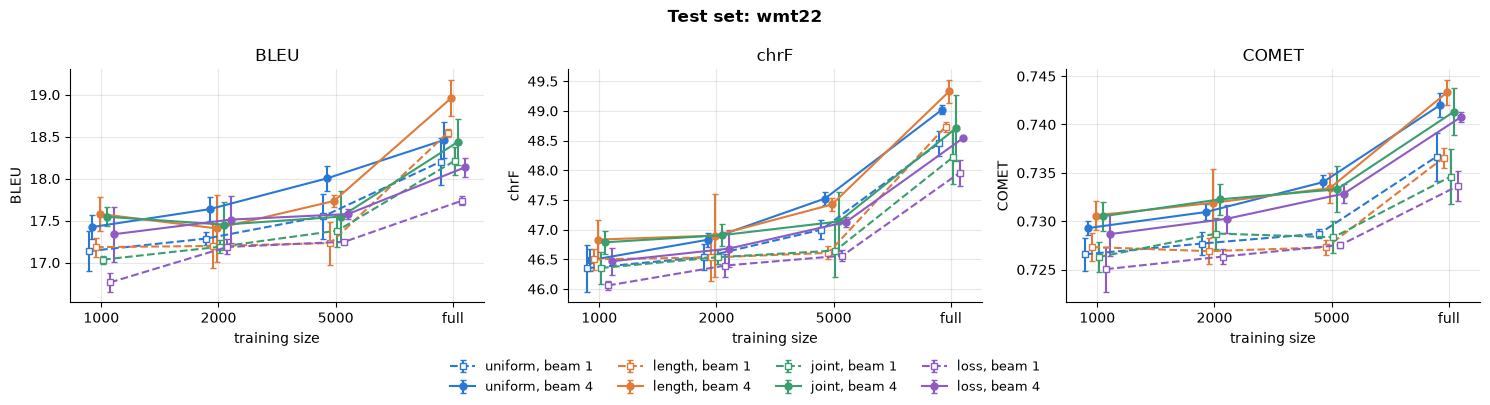

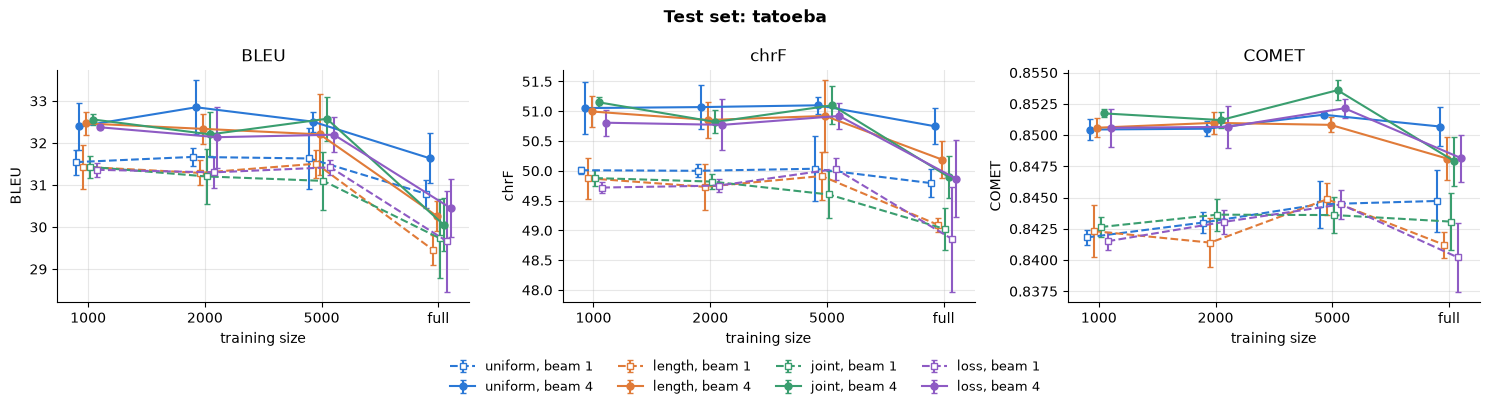

In [10]:
x = {size: i for i, size in enumerate(SIZES)}
for test_set in TEST_SETS:
    fig, axes = plt.subplots(1, len(METRICS), figsize=(5 * len(METRICS), 4))
    for ax, (metric, name) in zip(axes, METRICS.items()):
        for k, condition in enumerate(CONDITIONS):
            for beam in BEAMS:
                sub = test[(test["test_set"] == test_set) & (test["condition"] == condition) & (test["beam"] == beam)]
                g = sub.groupby("size")[metric].agg(["mean", "std"]).reindex(SIZES)
                offset = (k - (len(CONDITIONS) - 1) / 2) * 0.06 + (0.015 if beam == 4 else -0.015)
                ax.errorbar([x[s] + offset for s in SIZES], g["mean"], yerr=g["std"],
                            color=COLOUR[condition], linestyle="-" if beam == 4 else "--",
                            marker="o" if beam == 4 else "s", markerfacecolor=COLOUR[condition] if beam == 4 else "white",
                            markersize=5, capsize=2, linewidth=1.5,
                            label=f"{condition}, beam {beam}")
        ax.set_xticks(range(len(SIZES)), SIZES)
        ax.set_xlabel("training size")
        ax.set_ylabel(name)
        ax.set_title(name)
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, frameon=False, fontsize=9, ncol=len(CONDITIONS), loc="lower center")
    fig.suptitle(f"Test set: {test_set}", fontweight="bold")
    fig.tight_layout(rect=(0, 0.1, 1, 1))
    plt.show()

### 5.2 Gain from beam search (beam 4 minus greedy)

Paired by run: the same checkpoint decoded both ways, so the difference is computed per seed, then
mean ± std over the 3 seeds. Positive = beam search is better. Dots = individual seeds.

In [13]:
key = ["condition", "size", "seed", "test_set"]
wide = test.pivot_table(index=key, columns="beam", values=list(METRICS))
gain = pd.concat({m: wide[(m, 4)] - wide[(m, 1)] for m in METRICS}, axis=1).reset_index()

for test_set in TEST_SETS:
    s = gain[gain["test_set"] == test_set].groupby(["size", "condition"])[list(METRICS)].agg(["mean", "std"])
    parts = {}
    for metric, name in METRICS.items():
        fmt = "{:+.3f}" if metric == "comet" else "{:+.2f}"
        sd = "{:.3f}" if metric == "comet" else "{:.2f}"
        parts[name] = (s[(metric, "mean")].map(fmt.format) + " ± " + s[(metric, "std")].map(sd.format)).unstack()
    print(f"{test_set}: beam 4 minus greedy")
    display(pd.concat(parts, axis=1).reindex(index=SIZES, columns=pd.MultiIndex.from_product([list(METRICS.values()), CONDITIONS])))

wmt22: beam 4 minus greedy


BLEU                                                    chrF  \
           uniform        length         joint          loss       uniform   
size                                                                         
1000  +0.29 ± 0.38  +0.40 ± 0.32  +0.51 ± 0.09  +0.57 ± 0.24  +0.13 ± 0.26   
2000  +0.35 ± 0.13  +0.21 ± 0.26  +0.26 ± 0.33  +0.33 ± 0.25  +0.29 ± 0.15   
5000  +0.45 ± 0.29  +0.50 ± 0.21  +0.17 ± 0.20  +0.33 ± 0.07  +0.52 ± 0.08   
full  +0.26 ± 0.26  +0.41 ± 0.27  +0.23 ± 0.11  +0.40 ± 0.14  +0.57 ± 0.12   

                                                         COMET  \
            length         joint          loss         uniform   
size                                                             
1000  +0.33 ± 0.20  +0.43 ± 0.18  +0.41 ± 0.22  +0.003 ± 0.001   
2000  +0.37 ± 0.33  +0.37 ± 0.24  +0.29 ± 0.13  +0.003 ± 0.001   
5000  +0.81 ± 0.19  +0.49 ± 0.24  +0.57 ± 0.06  +0.005 ± 0.001   
full  +0.59 ± 0.11  +0.49 ± 0.21  +0.58 ± 0.21  +0.005 ± 0.002   

                                                      
              length           joint            loss  
size                                                  
1000  +0.003 ± 0.000  +0.004 ± 0.001  +0.004 ± 0.002  
2000  +0.005 ± 0.002  +0.004 ± 0.001  +0.004 ± 0.001  
5000  +0.006 ± 0.001  +0.005 ± 0.001  +0.005 ± 0.001  
full  +0.007 ± 0.001  +0.007 ± 0.001  +0.007 ± 0.001

tatoeba: beam 4 minus greedy


BLEU                                                    chrF  \
           uniform        length         joint          loss       uniform   
size                                                                         
1000  +0.85 ± 0.42  +1.03 ± 0.41  +1.13 ± 0.28  +1.01 ± 0.19  +1.04 ± 0.39   
2000  +1.18 ± 0.64  +1.05 ± 0.29  +1.00 ± 0.31  +0.84 ± 1.01  +1.07 ± 0.41   
5000  +0.88 ± 0.73  +0.70 ± 0.79  +1.48 ± 0.17  +0.78 ± 0.29  +1.06 ± 0.41   
full  +0.85 ± 0.32  +0.81 ± 0.21  +0.33 ± 0.53  +0.79 ± 0.63  +0.95 ± 0.20   

                                                         COMET  \
            length         joint          loss         uniform   
size                                                             
1000  +1.12 ± 0.44  +1.27 ± 0.22  +1.09 ± 0.21  +0.009 ± 0.001   
2000  +1.12 ± 0.37  +1.00 ± 0.07  +1.02 ± 0.44  +0.008 ± 0.001   
5000  +1.01 ± 0.39  +1.50 ± 0.18  +0.89 ± 0.17  +0.007 ± 0.002   
full  +1.10 ± 0.21  +0.88 ± 0.16  +1.02 ± 0.41  +0.006 ± 0.001   

                                                      
              length           joint            loss  
size                                                  
1000  +0.008 ± 0.002  +0.009 ± 0.001  +0.009 ± 0.001  
2000  +0.010 ± 0.001  +0.008 ± 0.001  +0.008 ± 0.002  
5000  +0.006 ± 0.001  +0.010 ± 0.002  +0.008 ± 0.001  
full  +0.007 ± 0.001  +0.005 ± 0.000  +0.008 ± 0.001

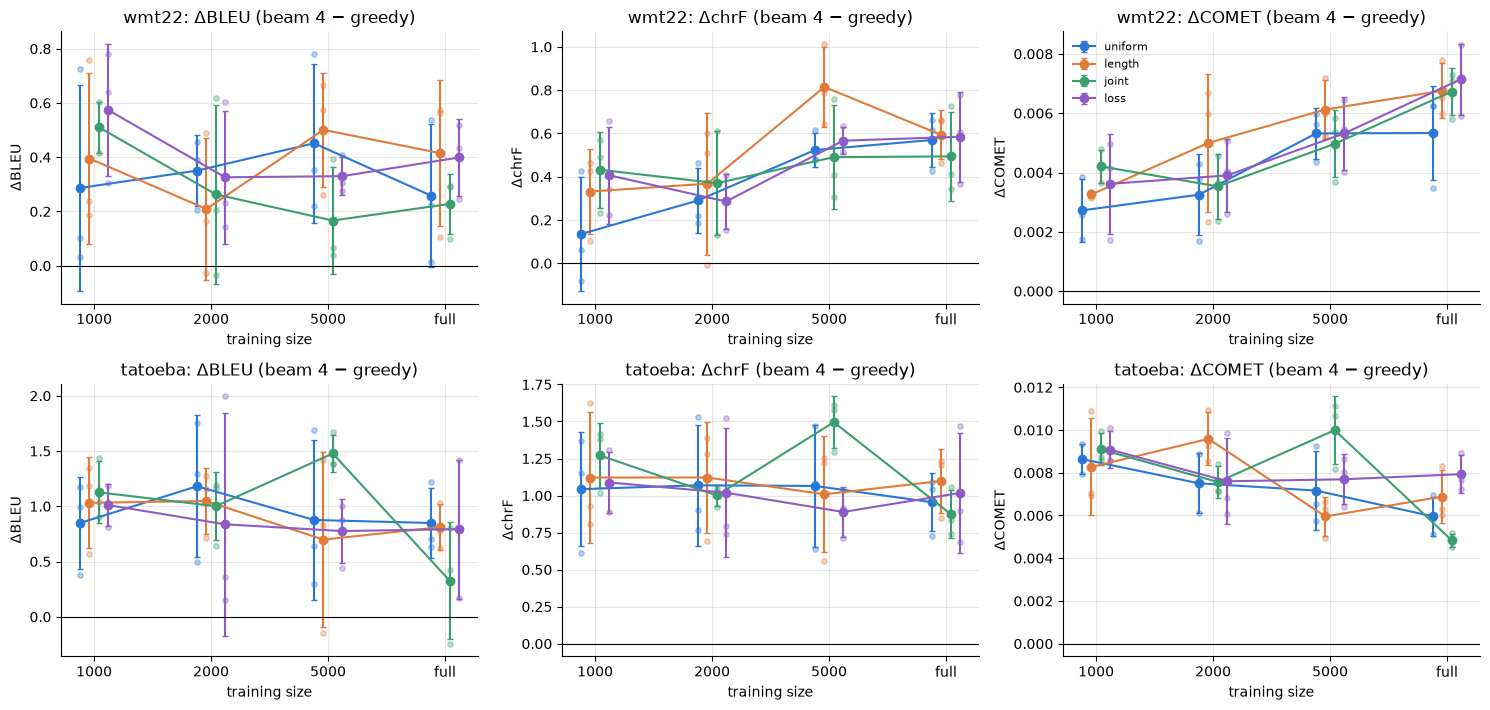

In [14]:
fig, axes = plt.subplots(len(TEST_SETS), len(METRICS), figsize=(5 * len(METRICS), 3.6 * len(TEST_SETS)), squeeze=False)
for i, test_set in enumerate(TEST_SETS):
    for j, (metric, name) in enumerate(METRICS.items()):
        ax = axes[i, j]
        for k, condition in enumerate(CONDITIONS):
            sub = gain[(gain["test_set"] == test_set) & (gain["condition"] == condition)]
            offset = (k - (len(CONDITIONS) - 1) / 2) * 0.08
            ax.scatter(sub["size"].map(x) + offset, sub[metric], color=COLOUR[condition], alpha=0.35, s=15)
            g = sub.groupby("size")[metric].agg(["mean", "std"]).reindex(SIZES)
            ax.errorbar([x[s] + offset for s in SIZES], g["mean"], yerr=g["std"], fmt="o-",
                        color=COLOUR[condition], capsize=2, linewidth=1.5, label=condition)
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_xticks(range(len(SIZES)), SIZES)
        ax.set_title(f"{test_set}: Δ{name} (beam 4 − greedy)")
        ax.set_xlabel("training size")
        ax.set_ylabel(f"Δ{name}")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)
axes[0, -1].legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## 6. Main figure

Test-set scores vs training size, beam 4 (the decoding used for the final results). Lines = mean over the 3 seeds, error bars = std, faint dots = individual seeds. Saved as `figures/main_results.png` and `.pdf` for the report.

In [ ]:
# Main figure of the report: test-set scores vs training size, beam 4, all conditions.
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
MAIN_BEAM = 4
SIZE_TICKS = ["1k", "2k", "5k", "full\n(15.4k)"]
TEST_NAMES = {"wmt22": f"WMT22 (n=1,875)", "tatoeba": f"Tatoeba (n=469)"}
x = {size: i for i, size in enumerate(SIZES)}

fig, axes = plt.subplots(len(TEST_SETS), len(METRICS), figsize=(13, 7.2), squeeze=False)
for i, test_set in enumerate(TEST_SETS):
    for j, (metric, name) in enumerate(METRICS.items()):
        ax = axes[i, j]
        for k, condition in enumerate(CONDITIONS):
            sub = test[(test["test_set"] == test_set) & (test["condition"] == condition) & (test["beam"] == MAIN_BEAM)]
            offset = (k - (len(CONDITIONS) - 1) / 2) * 0.07  # spread conditions so error bars don't overlap
            ax.scatter(sub["size"].map(x) + offset, sub[metric], color=COLOUR[condition], alpha=0.3, s=12,
                       linewidths=0)
            g = sub.groupby("size")[metric].agg(["mean", "std"]).reindex(SIZES)
            ax.errorbar([x[s] + offset for s in SIZES], g["mean"], yerr=g["std"], fmt="o-",
                        color=COLOUR[condition], markersize=5, capsize=2.5, linewidth=1.8,
                        label=condition, zorder=3)
        ax.set_xticks(range(len(SIZES)), SIZE_TICKS)
        ax.set_xlim(-0.4, len(SIZES) - 0.6)
        ax.grid(axis="y", alpha=0.3)
        if metric == "comet":
            ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=6, steps=[1, 2, 5, 10]))
            ax.yaxis.set_major_formatter(plt.FormatStrFormatter("%.3f"))
        ax.spines[["top", "right"]].set_visible(False)
        if i == 0:
            ax.set_title(name, fontsize=13, fontweight="bold")
        if i == len(TEST_SETS) - 1:
            ax.set_xlabel("training-set size")
        if j == 0:
            ax.set_ylabel(f"{TEST_NAMES[test_set]}\n\n{name}", fontsize=11)
        else:
            ax.set_ylabel(name)
for i in range(len(TEST_SETS)):
    for j in range(len(METRICS)):
        axes[i, j].text(-0.13 if j == 0 else -0.12, 1.04, f"({'abcdef'[i * len(METRICS) + j]})",
                        transform=axes[i, j].transAxes, fontsize=12, fontweight="bold", ha="right")
fig.align_ylabels(axes[:, 0])
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=len(CONDITIONS), loc="upper center",
           bbox_to_anchor=(0.5, 1.0), fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.95), h_pad=2.0)
fig.savefig(FIG_DIR / "main_results.png", dpi=200, bbox_inches="tight")
fig.savefig(FIG_DIR / "main_results.pdf", bbox_inches="tight")
plt.show()


## 7. Significance: paired bootstrap on sentence-level COMET

Is a condition really better (or worse) than uniform, or is the difference noise? Following Koehn (2004):

1. For every test sentence, take its COMET score under the condition and under uniform (same size, beam 4),
   each **averaged over the 3 seeds**, and compute the per-sentence difference $d_i$.
   The observed effect is $\bar d$ = mean difference over the test set.
2. Resample the test sentences **with replacement** $B = 10{,}000$ times (the same sentences for both
   systems, hence *paired*) and recompute $\bar d$ each time. This simulates drawing a new test set
   from the same distribution.
3. The 2.5th and 97.5th percentiles of the resampled $\bar d$ give a 95% confidence interval. The
   two-sided p-value is twice the share of resamples on the "wrong" side of 0.
4. There are 24 tests (3 conditions × 4 sizes × 2 test sets), so p-values are Holm-corrected.

Caveat: averaging over seeds tests whether the *seed-averaged* systems differ on these test sentences;
seed variance itself is not resampled. Small test sets (Tatoeba, 469 sentences) give wide intervals.


In [16]:
import numpy as np

N_BOOT = 10_000
BOOT_BEAM = 4
rng = np.random.default_rng(0)


def sentence_comet(output_dir):
    """Sentence-level COMET of one run, as a Series indexed by sentence id."""
    scores = json.loads((Path(output_dir) / "comet.json").read_text())["sentence_scores"]
    return pd.Series({s["id"]: s["score"] for s in scores})


# Per sentence: COMET averaged over the 3 seeds, for every (test set, size, condition).
runs_b = test[test["beam"] == BOOT_BEAM]
seed_avg = {key: pd.concat([sentence_comet(o) for o in g["output"]], axis=1).mean(axis=1)
            for key, g in runs_b.groupby(["test_set", "size", "condition"])}


def holm(p):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(p)
    order = np.argsort(p)
    adj = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1)
    out = np.empty_like(adj)
    out[order] = adj
    return out


rows = []
for test_set in TEST_SETS:
    for size in SIZES:
        base = seed_avg[(test_set, size, "uniform")]
        n = len(base)
        idx = rng.integers(0, n, size=(N_BOOT, n))  # same resamples for every condition at this size
        for condition in CONDITIONS[1:]:
            other = seed_avg[(test_set, size, condition)]
            assert other.index.equals(base.index)
            d = (other - base).to_numpy()
            boot = d[idx].mean(axis=1)
            p = 2 * min((boot <= 0).mean(), (boot >= 0).mean())
            rows.append({"test_set": test_set, "size": size, "condition": condition, "n": n,
                         "delta": d.mean(), "ci_low": np.percentile(boot, 2.5),
                         "ci_high": np.percentile(boot, 97.5), "p": max(p, 1 / N_BOOT)})
boot_res = pd.DataFrame(rows)
boot_res["p_holm"] = holm(boot_res["p"])

# Table: Δ COMET ×100 with 95% CI; * = significant after Holm correction (p < 0.05).
fmt = lambda r: (f"{100 * r.delta:+.2f} [{100 * r.ci_low:+.2f}, {100 * r.ci_high:+.2f}]"
                 + ("*" if r.p_holm < 0.05 else ""))
boot_res["cell"] = boot_res.apply(fmt, axis=1)
for test_set in TEST_SETS:
    print(f"{test_set}: COMET ×100, condition minus uniform (beam {BOOT_BEAM}), 95% CI; * = p_holm < 0.05")
    display(boot_res[boot_res["test_set"] == test_set]
            .pivot(index="size", columns="condition", values="cell")
            .reindex(index=SIZES, columns=CONDITIONS[1:]))
display(boot_res.drop(columns="cell").round(5))


wmt22: COMET ×100, condition minus uniform (beam 4), 95% CI; * = p_holm < 0.05


condition,length,joint,loss
size,,,
1000,"+0.13 [-0.02, +0.28]","+0.12 [-0.01, +0.26]","-0.06 [-0.21, +0.07]"
2000,"+0.10 [-0.05, +0.25]","+0.13 [-0.01, +0.27]","-0.07 [-0.22, +0.07]"
5000,"-0.06 [-0.21, +0.08]","-0.07 [-0.22, +0.07]","-0.12 [-0.26, +0.03]"
full,"+0.13 [-0.06, +0.32]","-0.07 [-0.26, +0.13]","-0.12 [-0.34, +0.09]"


tatoeba: COMET ×100, condition minus uniform (beam 4), 95% CI; * = p_holm < 0.05


condition,length,joint,loss
size,,,
1000,"+0.01 [-0.17, +0.23]","+0.13 [-0.05, +0.33]","+0.01 [-0.16, +0.20]"
2000,"+0.05 [-0.12, +0.22]","+0.07 [-0.11, +0.25]","+0.01 [-0.16, +0.19]"
5000,"-0.08 [-0.27, +0.10]","+0.20 [-0.02, +0.43]","+0.05 [-0.17, +0.28]"
full,"-0.26 [-0.56, +0.04]","-0.28 [-0.64, +0.07]","-0.25 [-0.55, +0.04]"


,test_set,size,condition,n,delta,ci_low,ci_high,p,p_holm
0,wmt22,1000,length,1875,0.00129,-0.00022,0.00279,0.0954,1.0
1,wmt22,1000,joint,1875,0.00121,-0.00006,0.00255,0.0668,1.0
2,wmt22,1000,loss,1875,-0.00064,-0.00206,0.00075,0.3628,1.0
3,wmt22,2000,length,1875,0.00095,-0.00051,0.00248,0.2012,1.0
4,wmt22,2000,joint,1875,0.00131,-0.00010,0.00274,0.0710,1.0
5,wmt22,2000,loss,1875,-0.00069,-0.00218,0.00074,0.3426,1.0
6,wmt22,5000,length,1875,-0.00061,-0.00205,0.00084,0.4148,1.0
7,wmt22,5000,joint,1875,-0.00073,-0.00218,0.00072,0.3280,1.0
8,wmt22,5000,loss,1875,-0.00118,-0.00261,0.00030,0.1158,1.0
9,wmt22,full,length,1875,0.00132,-0.00057,0.00324,0.1868,1.0
